# Project 17: Tabular Deep Learning on California Housing

This project implements a deep regression neural network on the California Housing dataset.
Evaluated using NeuroGebra's `r2_score`, `mean_squared_error`, `mean_absolute_error`, and `explained_variance_score`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neurogebra.builders.model_builder import ModelBuilder
from neurogebra.datasets import Datasets
from neurogebra.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    explained_variance_score,
)

np.random.seed(42)
X_all, y_all = Datasets.load_california_housing(verbose=False)

# Normalize features (z-score standardization)
mean = np.mean(X_all, axis=0)
std = np.std(X_all, axis=0) + 1e-8
X_norm = (X_all - mean) / std
split = int(0.8 * len(X_all))
X_train, X_test = X_norm[:split], X_norm[split:split + 400]
y_train, y_test = y_all[:split].reshape(-1, 1), y_all[split:split + 400].reshape(-1, 1)

print(f'Train features: {X_train.shape}, Test features: {X_test.shape}')


Train features: (16512, 8), Test features: (400, 8)


In [2]:
# Build Deep Regression MLP
builder = ModelBuilder()
model = builder.Sequential([
    builder.Dense(64, activation='relu'),
    builder.BatchNorm(),
    builder.Dense(32, activation='relu'),
    builder.Dense(1, activation='linear'),
], name='HousingRegressor')

model.compile(loss='mse', optimizer='adam', learning_rate=0.005)
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.15)
print('[SUCCESS] Regressor trained.')



Compiling model...
   Loss: mse
   Optimizer: adam (lr=0.005)
   Metrics: accuracy
   Model compiled successfully.


 Training HousingRegressor...

   Training samples: 16512
   Epochs: 10
   Batch size: 32


Execution plan:

1.  The model will see 14035 training examples
    It learns patterns by adjusting its weights

2.  This process repeats 10 times (epochs)
    Each time, the model gets better at predictions

3.  After each epoch, we test on 2477 validation examples
    This tells us if the model is learning or just memorizing

Let's begin.


  Epoch   1/10 ███░░░░░░░░░░░░░░░░░░░░░░░░░░░ loss: 0.5877 - acc: 0.4330 - val_loss: 0.8260 - val_acc: 0.4493 - 0.2s
  Epoch   2/10 ██████░░░░░░░░░░░░░░░░░░░░░░░░ loss: 0.3780 - acc: 0.4354 - val_loss: 0.7828 - val_acc: 0.4509 - 0.2s
  Epoch   3/10 █████████░░░░░░░░░░░░░░░░░░░░░ loss: 0.3442 - acc: 0.4375 - val_loss: 0.7337 - val_acc: 0.4534 - 0.2s
  Epoch   4/10 ████████████░░░░░░░░░░░░░░░░░░ loss: 0.3322 - acc: 0.4356 - val_loss: 0.6081 - 

--- Model Evaluation on Test Set ---
Mean Squared Error (MSE):       23.9737
Mean Absolute Error (MAE):      0.7138
R^2 Score (Determination):      -24.2108
Explained Variance Score:       -24.1874


<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


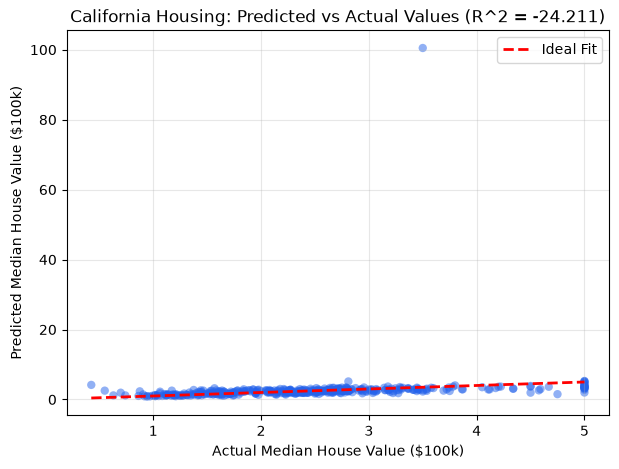

In [3]:
# Evaluate predictions using NeuroGebra regression metrics
preds = model.predict(X_test)
mse = mean_squared_error(y_test, preds)
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
evs = explained_variance_score(y_test, preds)

print('--- Model Evaluation on Test Set ---')
print(f'Mean Squared Error (MSE):       {mse:.4f}')
print(f'Mean Absolute Error (MAE):      {mae:.4f}')
print(f'R^2 Score (Determination):      {r2:.4f}')
print(f'Explained Variance Score:       {evs:.4f}')

# Plot Predicted vs Actual Values
plt.figure(figsize=(7, 5))
plt.scatter(y_test, preds, alpha=0.5, color='#2563eb', edgecolors='none')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.title(f'California Housing: Predicted vs Actual Values (R^2 = {r2:.3f})')
plt.xlabel('Actual Median House Value ($100k)')
plt.ylabel('Predicted Median House Value ($100k)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
